# Chapter 80: Cities, Agglomeration, Spatial Equilibrium, and Regional Multipliers

This notebook reruns four worked examples from the chapter: wages and rents after an amenity or productivity shock, a regional gap that shrinks or compounds, the local jobs that follow an exporter, and a public works multiplier with leakages. Every number is one of the chapter's hypothetical teaching numbers, not regional data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def undefined(reason):
    """Display text for a quantity with no value in this state."""
    return f"undefined ({reason})"


def rosen_roback(dA, da, h_r=0.5, h_a=10.0, f_A=8.0, f_r=0.25):
    """Linear Rosen-Roback: household dw - h_r dr + h_a da = 0, firm f_A dA - dw - f_r dr = 0.

    Principle: rosen-roback-spatial-equilibrium (ch080). Book: amenity shock gives dr = 13.333,
    dw = -3.333; productivity shock gives dr = 10.667, dw = 5.333 (thousand dollars).
    """
    dr = (f_A * dA + h_a * da) / (h_r + f_r)
    return {"dr": dr, "dw": f_A * dA - f_r * dr}


def geometric_path(g0, s, periods):
    """Gap path g_t = s^t g0 for t = 0..periods.

    Principle: circular-cumulative-causation (ch080). Book: s = 0.40 gives 10, 4, 1.6; s = 1.10 gives
    10, 11, 12.1; s = 0.60 gives 10, 6, 3.6 (million dollars).
    """
    return [g0 * s ** t for t in range(periods + 1)]


def local_multiplier(residents, wage, local_share, q_share, rev_per_job):
    """First-round local demand and nontradable jobs: demand = residents wage share; jobs = q demand / rev.

    Principle: local-employment-multiplier (ch080). Book: 85(80,000)(0.30) = 2.04 million and
    0.75(2.04 million)/60,000 = 25.5; 60 residents and 0.50 give 1.44 million and 12.
    """
    demand = residents * wage * local_share
    return {"demand": demand, "jobs": q_share * demand / rev_per_job}


def open_multiplier(c, t=0.0, m=0.0):
    """Keynesian spending multiplier 1/(1 - c(1 - t) + m).

    Principle: fiscal-multiplier-public-works (ch080). Book: 1/(1 - 0.60) = 2.5;
    1/(1 - 0.60(0.80) + 0.15) = 1/0.67 = 1.493.
    """
    return 1.0 / (1.0 - c * (1.0 - t) + m)


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(rosen_roback=rosen_roback)


growth = SimpleNamespace(geometric_path=geometric_path)


labor = SimpleNamespace(local_multiplier=local_multiplier)


macro = SimpleNamespace(open_multiplier=open_multiplier)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'rosen-roback-spatial-equilibrium': {'h_r': 0.5,
                                      'h_a': 10,
                                      'f_A': 8,
                                      'f_r': 0.25,
                                      'amenity_dr': 13.333,
                                      'amenity_dw': -3.333,
                                      'prod_dr': 10.667,
                                      'prod_dw': 5.333},
 'circular-cumulative-causation': {'g0': 10,
                                   's': 0.4,
                                   'g1': 4,
                                   'g2': 1.6,
                                   's_weak': 1.1,
                                   'g1_weak': 11,
                                   'g2_weak': 12.1,
                                   's_guarantee': 0.6,
                                   'g1_guarantee': 6,
                                   'g2_guarantee': 3.6},
 'local-employment-multiplier': {'direct': 100,
                                 'wage': 80000,
                                 'residents': 85,
                                 'local_share': 0.3,
                                 'rev_per_job': 60000,
                                 'q_share': 0.75,
                                 'demand': 2040000,
                                 'first': 25.5,
                                 'respend': 6,
                                 'm': 0.315,
                                 'residents_2': 60,
                                 'q_share_2': 0.5,
                                 'demand_2': 1440000,
                                 'first_2': 12,
                                 'respend_2': 3,
                                 'm_2': 0.15},
 'fiscal-multiplier-public-works': {'G': 10,
                                    'c': 0.6,
                                    'k': 2.5,
                                    'output': 25,
                                    't': 0.2,
                                    'm': 0.15,
                                    'k_leak': 1.493,
                                    'output_leak': 14.93,
                                    'crowd_out': 3,
                                    'net': 11.93,
                                    'measured': 1.193,
                                    'services': 12,
                                    'surplus': 2},
 'constructed': {'rosen-roback-spatial-equilibrium': {'shock': ['both']},
                 'local-employment-multiplier': {'mixed_first': {'60_0.75': 18, '85_0.50': 17}},
                 'fiscal-multiplier-public-works': {'c': [0.5, 0.75]}}}


LABEL = "Hypothetical teaching numbers, not regional data."


SHOCKS = {"amenity": (0, 1), "productivity": (1, 0), "both": (1, 1)}


def spatial_picture(shock="amenity"):
    dA, da = SHOCKS[shock]
    r = public.rosen_roback(dA, da)
    dr, dw = r["dr"], r["dw"]
    rs = np.linspace(0, 30, 100)
    fig, ax = new_figure()
    ax.plot(rs, 0.5 * rs, color=PALETTE["teal"], linewidth=1.4, linestyle="dashed")
    ax.plot(rs, -0.25 * rs, color=PALETTE["navy"], linewidth=1.4, linestyle="dashed")
    ax.plot(rs, 0.5 * rs - 10 * da, color=PALETTE["teal"], linewidth=2.2, label="households indifferent")
    ax.plot(rs, 8 * dA - 0.25 * rs, color=PALETTE["navy"], linewidth=2.2, label="firms at zero profit")
    mark(ax, 0, 0, col="grey")
    mark(ax, dr, dw, col="ink")
    ax.text(0.98, 0.04, f"new equilibrium: dr = {num(dr, 3)}, dw = {num(dw, 3)}", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=10.5, color=PALETTE["ink"],
            bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xlim(0, 30)
    ax.set_ylim(-12, 16)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Change in annual rent dr ($ thousand)")
    ax.set_ylabel("Change in annual wage dw ($ thousand)")
    shift = {"amenity": "The amenity lowers the household line by 10", "productivity": "Productivity raises the firm line by 8",
             "both": "The amenity lowers the household line by 10 and productivity raises the firm line by 8"}[shock]
    direction = "rises" if dw > 0 else ("falls" if dw < 0 else "is unchanged")
    metrics = {"Rent change dr ($000)": num(dr, 3), "Wage change dw ($000)": num(dw, 3), "Wage": direction}
    steps = [f"Households: dw - 0.5 dr + 10 x {da} = 0; firms: 8 x {dA} - dw - 0.25 dr = 0",
             f"Add the two: {8 * dA} + {10 * da} - 0.75 dr = 0",
             f"dr = {8 * dA + 10 * da} / 0.75 = {num(dr, 3)}",
             f"dw = {8 * dA} - 0.25 x {num(dr, 3)} = {num(dw, 3)}"]
    interp = (f"{LABEL} {shift}. Adding the two conditions gives {8 * dA + 10 * da} = 0.75 dr, so rent rises by "
              f"{num(dr, 3)} thousand and the wage {direction} by {num(abs(dw), 3)} thousand "
              f"(dw = {8 * dA} - 0.25 x {num(dr, 3)} = {num(dw, 3)}).")
    alt = (f"Wage change against rent change: the household and firm lines shift and cross at dr = {num(dr, 3)} and "
           f"dw = {num(dw, 3)} thousand dollars; dashed lines show the starting position at the origin.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


S_NAMES = {0.40: "base case", 0.60: "national guarantee", 1.10: "weak links and fiscal feedback"}


def gap_picture(s=0.40):
    path = growth.geometric_path(10, s, 5)
    fig, ax = new_figure()
    ts = np.arange(len(path))
    ax.bar(ts, path, color=PALETTE["teal" if s < 1 else "terracotta"], width=0.6)
    for t, g in zip(ts, path):
        ax.annotate(num(g), (t, g), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                    fontsize=10.5, color=PALETTE["ink"])
    ax.set_xticks(ts, [str(t) for t in ts])
    ax.set_ylim(0, 20)
    ax.set_xlabel("Year")
    ax.set_ylabel("Income gap ($ million)")
    ax.text(0.98, 0.97, f"s = {num(s)}: {S_NAMES[s]}", transform=ax.transAxes, ha="right", va="top", fontsize=11,
            color=PALETTE["ink"])
    trend = "grows" if s > 1 else "shrinks"
    metrics = {"Net reinforcement s": num(s), "Gap after one year": num(path[1]), "Gap after two years": num(path[2]),
               "Gap after five years": num(path[5]), "Gap": trend}
    steps = [f"g1 = {num(s)} x 10 = {num(path[1])}",
             f"g2 = {num(s)} x {num(path[1])} = {num(path[2])}",
             f"g5 = 10 x {num(s)}^5 = {num(path[5])}"]
    why = {0.40: "demand and migration carry 0.60, offset by 0.20",
           0.60: "the guarantee removes the 0.50 fiscal feedback and keeps the 0.60 demand term",
           1.10: "0.60 of demand plus 0.50 of fiscal feedback with no offset"}[s]
    interp = (f"{LABEL} Net reinforcement is s = {num(s)} ({why}). The gap moves from 10 to {num(s)} x 10 = "
              f"{num(path[1])} and then {num(s)} x {num(path[1])} = {num(path[2])} million, so it {trend} each year "
              f"and reaches {num(path[5])} million after five years.")
    alt = f"Bars of the regional income gap from year 0 to 5 at s = {num(s)}: 10, {num(path[1])}, {num(path[2])}, and {num(path[5])} in year 5."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def local_picture(res=85, qshare=0.75):
    b = BV["local-employment-multiplier"]
    r = labor.local_multiplier(res, b["wage"], b["local_share"], qshare, b["rev_per_job"])
    demand, first = r["demand"], r["jobs"]
    book = {(85, 0.75): b["respend"], (60, 0.50): b["respend_2"]}.get((res, qshare))
    fig, (ax, bx) = new_figure(ncols=2)
    bar_compare(ax, ["Payroll", "Local demand"], [8.0, demand / 1e6], colors=["grey", "teal"],
                value_labels=["8.00", num(demand / 1e6)], ylabel="$ million a year", xlabel="Spending")
    ax.set_ylim(0, 10)
    names = ["Direct", "First round"] + (["Re-spending"] if book is not None else [])
    vals = [100, first] + ([book] if book is not None else [])
    bar_compare(bx, names, vals, colors=["grey", "gold", "navy"][:len(vals)],
                value_labels=[num(v, 1) for v in vals], ylabel="Jobs", xlabel="Jobs")
    bx.set_ylim(0, 120)
    metrics = {"Local demand ($ million)": num(demand / 1e6), "First-round jobs": num(first, 1)}
    steps = [f"Demand = {res} x 80,000 x 0.30 = {num(demand, 0)}",
             f"First round = {num(qshare)} x {num(demand, 0)} / 60,000 = {num(first, 1)}"]
    if book is not None:
        m = (first + book) / 100
        metrics["Re-spending jobs"] = num(book, 0)
        metrics["Multiplier m"] = num(m, 3)
        steps.append(f"m = ({num(first, 1)} + {book}) / 100 = {num(m, 3)}")
        tail = f" With the book's {book} re-spending jobs, m = ({num(first, 1)} + {book}) / 100 = {num(m, 3)}."
    else:
        metrics["Multiplier m"] = undefined("re-spending not given for this mix")
        tail = (" The book gives re-spending only for its two cases, so this mixed case shows the first round only.")
    interp = (f"{LABEL} {res} resident workers spend 30 percent locally: {res} x 80,000 x 0.30 = "
              f"{num(demand / 1e6)} million. With {num(100 * qshare, 0)} percent met by more output, the first round is "
              f"{num(qshare)} x {num(demand, 0)} / 60,000 = {num(first, 1)} jobs.{tail}")
    alt = (f"Left: payroll 8 million and local demand {num(demand / 1e6)} million. Right: 100 direct jobs and "
           f"{num(first, 1)} first-round local jobs" + (f" plus {book} from re-spending." if book is not None else "."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def works_picture(c=0.60, leak="none"):
    b = BV["fiscal-multiplier-public-works"]
    t, m = (0.0, 0.0) if leak == "none" else (b["t"], b["m"])
    k = macro.open_multiplier(c, t, m)
    G, crowd = b["G"], b["crowd_out"]
    out = k * G
    net = out - crowd
    ratio = c * (1 - t) - m
    rounds = [G * ratio ** j for j in range(8)]
    fig, ax = new_figure()
    ax.bar(np.arange(8), rounds, color=PALETTE["teal"], width=0.6)
    for j in range(3):
        ax.annotate(num(rounds[j]), (j, rounds[j]), xytext=(0, 4), textcoords="offset points", ha="center",
                    va="bottom", fontsize=10.5, color=PALETTE["ink"])
    ax.set_xticks(np.arange(8), [str(j + 1) for j in range(8)])
    ax.set_ylim(0, 13)
    ax.set_xlabel("Spending round")
    ax.set_ylabel("Output added in the round ($ million)")
    ax.text(0.98, 0.97, f"all rounds (8 shown): {num(k, 3)} x 10 = {num(out)} million\nnet of 3 crowded out: {num(net)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=10.5, color=PALETTE["ink"], linespacing=1.4)
    denom = 1 - c * (1 - t) + m
    metrics = {"Multiplier k": num(k, 3), "Output gain ($ million)": num(out), "Net of crowd-out ($ million)": num(net),
               "Measured multiplier": num(net / G, 3), "Project surplus ($ million)": num(b["services"] - G)}
    if leak == "none":
        d_line = f"1 - {num(c)} = {num(denom)}"
    else:
        d_line = f"1 - {num(c)} x (1 - 0.20) + 0.15 = 1 - {num(c * 0.8)} + 0.15 = {num(denom)}"
    steps = [d_line,
             f"k = 1 / {num(denom)} = {num(k, 3)}",
             f"Output = {num(k, 3)} x 10 = {num(out)}",
             f"Net of crowd-out = {num(out)} - 3 = {num(net)}; measured {num(net)} / 10 = {num(net / G, 3)}",
             "Project surplus = 12 - 10 = 2, a separate ledger"]
    interp = (f"{LABEL} The denominator is {d_line}, so k = {num(k, 3)} and 10 million of repairs adds "
              f"{num(k, 3)} x 10 = {num(out)} million in total. Subtracting the 3 million of crowded-out private "
              f"output leaves {num(net)} million, a measured multiplier of {num(net / G, 3)}. The project's own value "
              f"is 12 - 10 = 2 million, a separate question.")
    alt = (f"Bars of output added in each spending round, starting at 10 million and shrinking by a factor "
           f"{num(ratio)}; the first eight rounds are shown, and the full series sums to {num(out)} million.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Rosen-Roback spatial equilibrium: wages and rents

Changes are in thousands of dollars a year.

$$\Delta V=\Delta w-0.5\Delta r+10\Delta a, \qquad \Delta\Pi=8\Delta A-\Delta w-0.25\Delta r$$

An amenity shock gives $-0.25\Delta r-0.5\Delta r+10=0$; a productivity shock gives $8-0.5\Delta r-0.25\Delta r=0$.

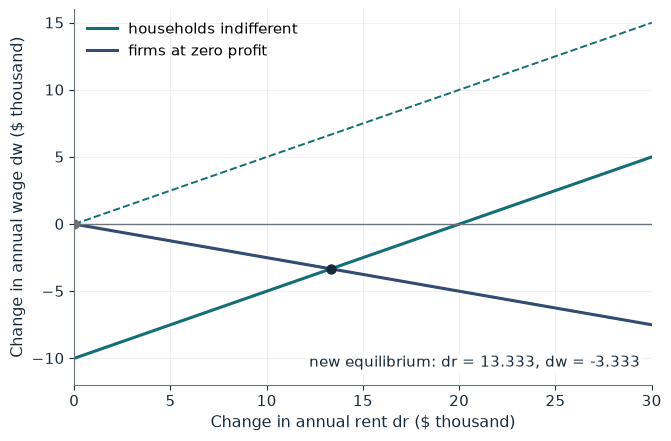

Rent change dr ($000)  13.333
Wage change dw ($000)  -3.333
Wage                   falls

Worked steps:
  1. Households: dw - 0.5 dr + 10 x 1 = 0; firms: 8 x 0 - dw - 0.25 dr = 0
  2. Add the two: 0 + 10 - 0.75 dr = 0
  3. dr = 10 / 0.75 = 13.333
  4. dw = 0 - 0.25 x 13.333 = -3.333

Hypothetical teaching numbers, not regional data. The amenity lowers the household line by 10. Adding the two conditions gives 10 = 0.75 dr, so rent rises by 13.333 thousand and the wage falls by 3.333 thousand (dw = 0 - 0.25 x 13.333 = -3.333).


In [2]:
show(spatial_picture(shock='amenity'))

Change one input, `shock`, and hold the others at the book's values:

In [3]:
sweep(spatial_picture, 'shock', ['amenity', 'productivity', 'both'], {}, ['Rent change dr ($000)', 'Wage change dw ($000)'])

shock | Rent change dr ($000) | Wage change dw ($000)
amenity | 13.333 | -3.333
productivity | 10.667 | 5.333
both | 24.000 | 2.000


Rent rises under both shocks (13.333 and 10.667 thousand), but the wage falls by 3.333 after the amenity and rises by 5.333 after the productivity gain. Both together give 24 and 2.

## 2. Circular cumulative causation: a gap that feeds on itself

The income gap starts at \$10 million and each year carries a share $s$ forward.

$$g_1=0.40(\$10\text{ million})=\$4\text{ million}, \qquad g_2=0.40(\$4\text{ million})=\$1.6\text{ million}$$

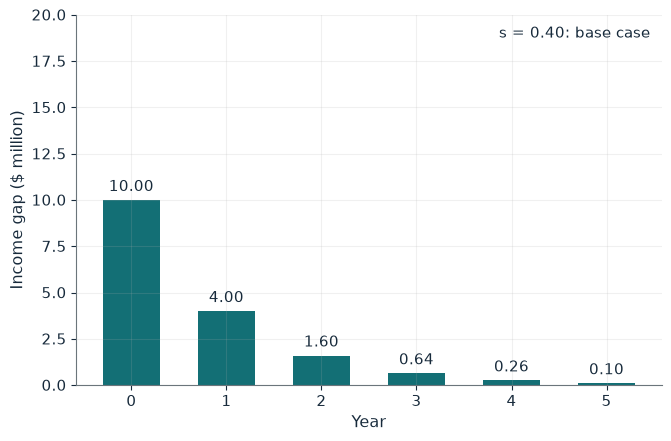

Net reinforcement s   0.40
Gap after one year    4.00
Gap after two years   1.60
Gap after five years  0.10
Gap                   shrinks

Worked steps:
  1. g1 = 0.40 x 10 = 4.00
  2. g2 = 0.40 x 4.00 = 1.60
  3. g5 = 10 x 0.40^5 = 0.10

Hypothetical teaching numbers, not regional data. Net reinforcement is s = 0.40 (demand and migration carry 0.60, offset by 0.20). The gap moves from 10 to 0.40 x 10 = 4.00 and then 0.40 x 4.00 = 1.60 million, so it shrinks each year and reaches 0.10 million after five years.


In [4]:
show(gap_picture(s=0.40))

Change one input, `s`, and hold the others at the book's values:

In [5]:
sweep(gap_picture, 's', [0.4, 0.6, 1.1], {}, ['Gap after one year', 'Gap after two years', 'Gap after five years'])

s | Gap after one year | Gap after two years | Gap after five years
0.4 | 4.00 | 1.60 | 0.10
0.6 | 6.00 | 3.60 | 0.78
1.1 | 11.00 | 12.10 | 16.11


With s = 0.40 the gap fades (4, then 1.6). The guarantee case s = 0.60 gives 6 and 3.6; weak links push s to 1.10 and the gap grows to 11 and 12.1.

## 3. Local employment multiplier

An exporter adds 100 jobs at \$80,000; resident workers spend 30 percent locally.

$$85(\$80{,}000)(0.30)=\$2.04\text{ million}, \qquad \frac{0.75(\$2.04\text{ million})}{\$60{,}000}=25.5$$

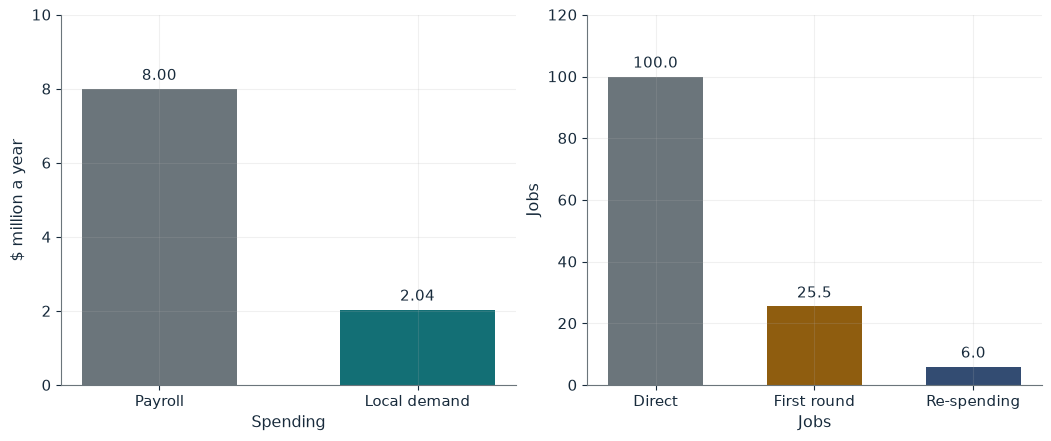

Local demand ($ million)  2.04
First-round jobs          25.5
Re-spending jobs          6
Multiplier m              0.315

Worked steps:
  1. Demand = 85 x 80,000 x 0.30 = 2,040,000
  2. First round = 0.75 x 2,040,000 / 60,000 = 25.5
  3. m = (25.5 + 6) / 100 = 0.315

Hypothetical teaching numbers, not regional data. 85 resident workers spend 30 percent locally: 85 x 80,000 x 0.30 = 2.04 million. With 75 percent met by more output, the first round is 0.75 x 2,040,000 / 60,000 = 25.5 jobs. With the book's 6 re-spending jobs, m = (25.5 + 6) / 100 = 0.315.


In [6]:
show(local_picture(res=85, qshare=0.75))

Change one input, `res`, and hold the others at the book's values:

In [7]:
sweep(local_picture, 'res', [60, 85], {'qshare': 0.75}, ['Local demand ($ million)', 'First-round jobs'])

res | Local demand ($ million) | First-round jobs
60 | 1.44 | 18.0
85 | 2.04 | 25.5


With 85 residents the first round is 25.5 jobs and, with the book's 6 re-spending jobs, m = 0.315. The book's constrained case (60 residents, `qshare=0.50`) gives 12 jobs and m = 0.15; the mixed cases show the first round only.

## 4. Fiscal multiplier and public works

\$10 million of repairs with $c=0.60$.

$$k_G=\frac{1}{1-0.60}=2.5, \qquad k_G=\frac{1}{1-0.60(1-0.20)+0.15}=\frac{1}{0.67}\approx1.493$$

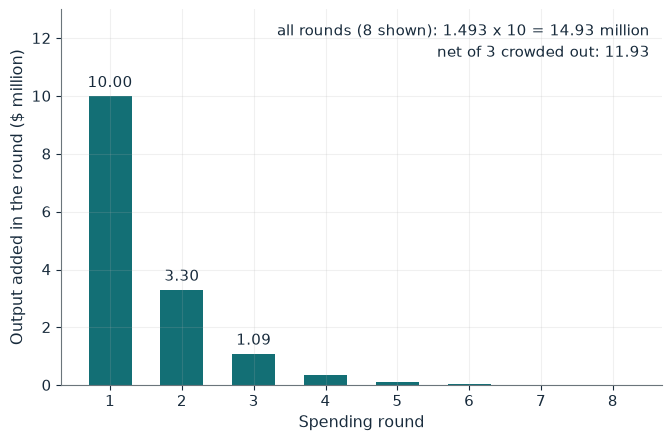

Multiplier k                  1.493
Output gain ($ million)       14.93
Net of crowd-out ($ million)  11.93
Measured multiplier           1.193
Project surplus ($ million)   2.00

Worked steps:
  1. 1 - 0.60 x (1 - 0.20) + 0.15 = 1 - 0.48 + 0.15 = 0.67
  2. k = 1 / 0.67 = 1.493
  3. Output = 1.493 x 10 = 14.93
  4. Net of crowd-out = 14.93 - 3 = 11.93; measured 11.93 / 10 = 1.193
  5. Project surplus = 12 - 10 = 2, a separate ledger

Hypothetical teaching numbers, not regional data. The denominator is 1 - 0.60 x (1 - 0.20) + 0.15 = 1 - 0.48 + 0.15 = 0.67, so k = 1.493 and 10 million of repairs adds 1.493 x 10 = 14.93 million in total. Subtracting the 3 million of crowded-out private output leaves 11.93 million, a measured multiplier of 1.193. The project's own value is 12 - 10 = 2 million, a separate question.


In [8]:
show(works_picture(c=0.60, leak='leak'))

Change one input, `c`, and hold the others at the book's values:

In [9]:
sweep(works_picture, 'c', [0.5, 0.6, 0.75], {'leak': 'leak'}, ['Multiplier k', 'Output gain ($ million)', 'Net of crowd-out ($ million)'])

c | Multiplier k | Output gain ($ million) | Net of crowd-out ($ million)
0.5 | 1.333 | 13.33 | 10.33
0.6 | 1.493 | 14.93 | 11.93
0.75 | 1.818 | 18.18 | 15.18


With taxes and imports the multiplier is 1.493, so output rises 14.93 million, 11.93 after 3 million of crowding out, a measured multiplier of 1.193. The project's own surplus, 2 million, is a separate ledger.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

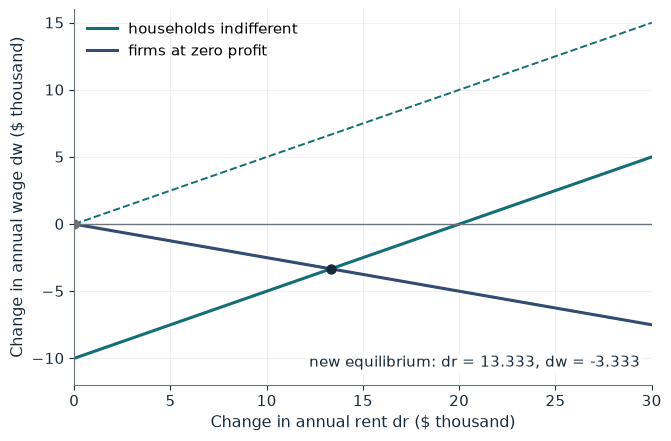

Rent change dr ($000)  13.333
Wage change dw ($000)  -3.333
Wage                   falls

Worked steps:
  1. Households: dw - 0.5 dr + 10 x 1 = 0; firms: 8 x 0 - dw - 0.25 dr = 0
  2. Add the two: 0 + 10 - 0.75 dr = 0
  3. dr = 10 / 0.75 = 13.333
  4. dw = 0 - 0.25 x 13.333 = -3.333

Hypothetical teaching numbers, not regional data. The amenity lowers the household line by 10. Adding the two conditions gives 10 = 0.75 dr, so rent rises by 13.333 thousand and the wage falls by 3.333 thousand (dw = 0 - 0.25 x 13.333 = -3.333).


In [10]:
show(spatial_picture(shock='amenity'))

## Practice

**1.** With both a one-unit amenity and a one-unit productivity shock, what are dr and dw?

<details><summary>Answer</summary>

8 + 10 = 0.75 dr, so dr = 24 and dw = 8 - 0.25 x 24 = 2 (thousand dollars).

</details>

**2.** Under the national guarantee (s = 0.60), what is the gap after one and two years?

<details><summary>Answer</summary>

0.60 x 10 = 6 and 0.60 x 6 = 3.6 million.

</details>

**3.** At c = 0.75 with t = 0.20 and m = 0.15, what are the multiplier and the output gain?

<details><summary>Answer</summary>

1 / (1 - 0.75 x 0.80 + 0.15) = 1 / 0.55 = 1.818, so output rises 18.18 million.

</details>